<a href="https://colab.research.google.com/github/Emil-888/Data-Science/blob/main/Copia_de_Copia_de_Clase_5_2_Data_Science_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Science
_________________________________
Clase: 02  
Tema: Estadística Descriptiva (EDA)
_________________________________


# Estadística Descriptiva

Nos encontramos en el segundo paso de nuestro roadmap de EDA:
1. Evaluación de calidad
2. Overview y estadística descriptiva
3. Estudio  de variables

En nuestro primer abordaje, conocimos las características de forma de nuestro dataset y revisamos su calidad: valores faltantes, duplicados, etc. La Estadística Descriptiva será nuestra segunda herramienta para trabajar sobre un problema y sus datasets. En la próxima clase, profundizaremos sobre las técnicas de visualización.

Continuaremos nuestra exploración de Sydney Housing Prices.



-------------------------------------------------------------


# Imports


Cargaremos las librerías que el estudiante ya conoce.

In [2]:
import pandas as pd
import numpy as np

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

Montaremos la unidad de Drive para acceder al archivo. Alternativamente, podemos subirlo directamente desde la interfaz de Colab en esta misma sesión y utilizarlo desde aquí.

In [4]:
# df = pd.read_csv('/content/drive/MyDrive/SydneyHousePrices.csv.zip') # Completar con la ruta de tu Drive
df = pd.read_csv('/content/SydneyHousePrices (1).csv') # Utilizar esta línea si cargaste el archivo en la sesión de Colab

In [5]:
display(df)

,Date,Id,suburb,postalCode,sellPrice,bed,bath,car,propType
0,2019-06-19,1,Avalon Beach,2107,1210000,4.0,2.0,2.0,house
1,2019-06-13,2,Avalon Beach,2107,2250000,4.0,3.0,4.0,house
2,2019-06-07,3,Whale Beach,2107,2920000,3.0,3.0,2.0,house
3,2019-05-28,4,Avalon Beach,2107,1530000,3.0,1.0,2.0,house
4,2019-05-22,5,Whale Beach,2107,8000000,5.0,4.0,4.0,house
...,...,...,...,...,...,...,...,...,...
198250,2018-01-30,198251,St Helens Park,2560,560000,3.0,1.0,1.0,house
198251,2018-01-29,198252,Leumeah,2560,691000,3.0,1.0,3.0,house
198252,2018-01-25,198253,Glen Alpine,2560,960000,5.0,3.0,2.0,house
198253,2018-01-25,198254,Campbelltown,2560,450000,2.0,1.0,1.0,house


# Exploración

Recordemos las columnas:

- Id: es simplemente un valor numérico que identifica a la propiedad
- Date: Fecha de publicación
- suburb: Barrio
- postalCode: Código postal
- sellPrice: Precio de venta
- bed: Cantidad de camas
- Car: Cantidad de lugares de estacionamiento
- propType: Tipo de propiedad

Ya conocemos el método .info() para conocer los tipos de variable.

Y recordamos la dimensión del dataset

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198255 entries, 0 to 198254
Data columns (total 9 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Date        198255 non-null  object 
 1   Id          198255 non-null  int64  
 2   suburb      198255 non-null  object 
 3   postalCode  198255 non-null  int64  
 4   sellPrice   198255 non-null  int64  
 5   bed         198101 non-null  float64
 6   bath        198254 non-null  float64
 7   car         180131 non-null  float64
 8   propType    198254 non-null  object 
dtypes: float64(3), int64(3), object(3)
memory usage: 13.6+ MB


# Estadística

## Funciones individuales

Como ejercicio, el estudiante podría calcular las distintas medidas estudiadas en clase:

Posicion central. Media, moda, mediana

Dispersión. Rango, desvío estándar, varianza, percentiles y cuartiles, IQR

Lo cierto es que diferentes paquetes ya tienen implementaciones que no es necesario replicar. Paquetes muy comunes para estas y otras operaciones, son **numpy** (sobre np.arrays) y **scipy.stats**. **Pandas** también las incluye como operaciones vectoriales (sobre pd.DataFrames y pd.Series)

Por ejemplo:


### Medidas de posición central

Media:

In [7]:
df ['sellPrice'].mean()

np.float64(1272081.3436231117)

Mediana:

In [8]:
df['sellPrice'].median()

989000.0

Moda:

In [9]:
df['propType'].mode()

,propType
0,house


### Medidas de disperción

Varianza y desviación estandar:

In [10]:
df['sellPrice'].var()

48580395736736.125

In [11]:
grupo_a = [9, 10, 10, 10, 11]
grupo_b = [1, 5, 10 ,15 ,19]

In [12]:
df['sellPrice'].std()

6969963.826070844

Rango:

In [13]:
# valor maximo
valor_máximo =df ['sellPrice'].max()
print(valor_máximo)

2147483647


In [14]:
#valor minimo
valor_mínimo =df ['sellPrice'].min()
print(valor_mínimo)

1


Percentiles y cuartiles:

In [15]:
# Percentiles
percentiles = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
for percentil in percentiles:
    print(f"Percentil {percentil*100}: {df['sellPrice'].quantile(percentil)}")

Percentil 10.0: 555000.0
Percentil 20.0: 670000.0
Percentil 30.0: 770000.0
Percentil 40.0: 870000.0
Percentil 50.0: 989000.0
Percentil 60.0: 1170000.0
Percentil 70.0: 1355000.0
Percentil 80.0: 1630000.0
Percentil 90.0: 2150000.0
Percentil 100: 2147483647.0


In [16]:
cuartiles = [0.25, 0.5, 0.75, 1]
for cuartil in cuartiles:
    print(f"Cuartil {cuartil*100}: {df['sellPrice'].quantile(cuartil)}")

Cuartil 25.0: 720000.0
Cuartil 50.0: 989000.0
Cuartil 75.0: 1480000.0
Cuartil 100: 2147483647.0


In [17]:
q1 = np.quantile(df['sellPrice'], 0.25)
q3 = np.quantile(df['sellPrice'], 0.75)

In [18]:
iqr = q3 - q1
print(iqr)

760000.0


## Reportes por variable
Podemos hacer cálculos individuales cuando lo necesitemos. Pero contamos con funciones de reportería que harán varios cálculos en simultáneo e incluso de varias variables a la vez. El estudiante ya ha usado algunas de ellas. Por ejemplo, en la notebook 1 ya se hizo:

### Variables numerícas

In [20]:
df['sellPrice'].describe()

,sellPrice
count,1.982550e+05
mean,1.272081e+06
std,6.969964e+06
min,1.000000e+00
25%,7.200000e+05
50%,9.890000e+05
75%,1.480000e+06
max,2.147484e+09


Y ahora usaremos, para ver todas las variables al mismo tiempo, df.describe sin diferenciar columna.

In [21]:
df.describe()

,Id,postalCode,sellPrice,bed,bath,car
count,198255.000000,198255.000000,1.982550e+05,198101.000000,198254.000000,180131.000000
mean,99128.000000,2195.102121,1.272081e+06,3.515262,1.890842,1.936413
std,57231.433146,192.542111,6.969964e+06,1.067441,0.926717,1.060104
min,1.000000,2000.000000,1.000000e+00,1.000000,1.000000,1.000000
25%,49564.500000,2081.000000,7.200000e+05,3.000000,1.000000,1.000000
50%,99128.000000,2144.000000,9.890000e+05,3.000000,2.000000,2.000000
75%,148691.500000,2210.000000,1.480000e+06,4.000000,2.000000,2.000000
max,198255.000000,4878.000000,2.147484e+09,99.000000,99.000000,41.000000


Aquí podemos ver de un vistazo la cantidad de muestras, media, desvío estándar, valores mínimo y máximo, y cuartiles (percentiles 25, 50 y 75).

### Contestar
1. ¿Qué variables tienen mayor dispersión?  *sellPrice es la variable con mayor dispersión ya que cuenta con una mayor desviación estándar.*
2. ¿Qué puede decir acerca de la media de las variables bed, bath y car? *Poseen valores atípicos que sesgan la media ligermente hacia arriba superando a la mediana, en el caso de la variable bed. Para bath y car, la media es bastante cercana a la mediana por lo tanto no hay tanta presencia de valores atípicos como en el caso de bed.*
3. ¿Qué conclusión puede extraer del reporte de la variable Id? *No aporta mucho significado para el negocio ya que es una clave primaria.*
4. ¿Qué conclusión puede extraer del reporte de la variable postalCode?
*Se puede tratar como una variable categórica.*

### Variables categorícas

Por otro lado, ¿por qué las variables categóricas no están? Ciertamente, carecería de sentido replicar exactamente el mismo análisis. Podemos pedir a la función describe, que las incluya con nuevos cómputos. ¿Qué nueva información encuentra?

Por último, esta función puede no ser práctica al explorar datasets grandes. Se invita al estudiante a investigar, para las próximas clases, otros paquetes y funciones de exploración -se sorprenderá con lo que puede encontrar.

In [22]:
df.describe(include='all')

,Date,Id,suburb,postalCode,sellPrice,bed,bath,car,propType
count,198255,198255.000000,198255,198255.000000,1.982550e+05,198101.000000,198254.000000,180131.000000,198254
unique,4683,NaN,678,NaN,NaN,NaN,NaN,NaN,8
top,2015-03-28,NaN,Castle Hill,NaN,NaN,NaN,NaN,NaN,house
freq,304,NaN,1250,NaN,NaN,NaN,NaN,NaN,169019
mean,NaN,99128.000000,NaN,2195.102121,1.272081e+06,3.515262,1.890842,1.936413,NaN
std,NaN,57231.433146,NaN,192.542111,6.969964e+06,1.067441,0.926717,1.060104,NaN
min,NaN,1.000000,NaN,2000.000000,1.000000e+00,1.000000,1.000000,1.000000,NaN
25%,NaN,49564.500000,NaN,2081.000000,7.200000e+05,3.000000,1.000000,1.000000,NaN
50%,NaN,99128.000000,NaN,2144.000000,9.890000e+05,3.000000,2.000000,2.000000,NaN
75%,NaN,148691.500000,NaN,2210.000000,1.480000e+06,4.000000,2.000000,2.000000,NaN


In [24]:
df.describe(include=['object', 'category'])

,Date,suburb,propType
count,198255,198255,198254
unique,4683,678,8
top,2015-03-28,Castle Hill,house
freq,304,1250,169019


**Interpretación:**

* count → cuántos datos hay (no nulos)
* unique → cuántos valores distintos hay
* top → el valor que más se repite
* freq → cuántas veces se repite ese valor

## Outliers

Algunas consideraciones sobre los valores extremos:
1. No necesariamente hay que quitar los valores extremos. Si se comprueba que son el resultado de un error de medición ("pusieron un cero de más", en este caso), sí podemos quitarlos.
2. Si no son el resultado de un error, o no lo sabemos, pueden tener un valor en si mismo: así como hemos pensado en separar las casas para un análisis diferenciado, también podríamos analizar las propiedades extremadamente caras por separado (también, las extremadamente baratas).
3. A veces queremos intencionalmente estudiar los valores extremos.
4. El criterio de 1.5 IQRs es una regla matemática general. NO significa que tenga sentido para todo dataset, es simplemente un criterio "a ciegas". Debemos estudiar cuidadosamente nuestros datos para identificar realmente datos que valga la pena reconocer como atípicos por algún motivo y no apresurarnos a descararlos.

Estos valores extremos son parte de lo que se conoce como "outliers" o "valores atípicos".

Detectandolos manualmente por la [formula de Tukey](https://es.wikipedia.org/wiki/Valor_at%C3%ADpico)

In [26]:
nombre_columna_numerica = 'sellPrice'
columna_numerica = df[nombre_columna_numerica].dropna()

In [27]:
q1 = columna_numerica.quantile(0.25)
q3 = columna_numerica.quantile(0.75)

In [28]:
iqr = q3 - q1

In [29]:
q1, q3, iqr

(np.float64(720000.0), np.float64(1480000.0), np.float64(760000.0))

In [35]:
limite_inferior = q1 - (1.5 * iqr)
limite_inferior

np.float64(-420000.0)

In [38]:
limite_superior = q3 + (1.5 * iqr)
limite_superior

np.float64(2620000.0)

In [39]:
inferiores = columna_numerica[columna_numerica < limite_inferior]
inferiores

,sellPrice


In [40]:
superiores = columna_numerica[columna_numerica > limite_superior]
superiores

,sellPrice
2,2920000
4,8000000
66,2850000
86,2870000
104,9500000
...,...
196982,3261000
197054,3400000
197131,9022000
197153,10370000


In [19]:
def analizar_outliers(df, columna_numerica, columna_categorica=None):

    """

    Genera un boxplot y devuelve los valores atípicos inferiores y superiores.

    Parámetros

    ----------

    df : pandas.DataFrame

        DataFrame a analizar.

    columna_numerica : str

        Nombre de la columna numérica.

    columna_categorica : str, opcional

        Nombre de la columna categórica utilizada para diferenciar

        los boxplots.

    Retorna

    -------

    pandas.DataFrame

        DataFrame con dos columnas:

        - outliers_inferiores

        - outliers_superiores

    """

    # Validaciones

    if columna_numerica not in df.columns:

        raise ValueError(

            f"La columna '{columna_numerica}' no existe en el DataFrame."

        )

    if columna_categorica is not None and columna_categorica not in df.columns:

        raise ValueError(

            f"La columna '{columna_categorica}' no existe en el DataFrame."

        )

    # ---------------------------------------------------------

    # 1. Generar boxplot

    # ---------------------------------------------------------

    plt.figure(figsize=(10, 6))

    if columna_categorica is None:

        sns.boxplot(data=df, y=columna_numerica)

        plt.title(f"Boxplot de {columna_numerica}")

    else:

        sns.boxplot(

            data=df,

            x=columna_categorica,

            y=columna_numerica

        )

        plt.title(

            f"Boxplot de {columna_numerica} por {columna_categorica}"

        )

        plt.xticks(rotation=45)

    plt.tight_layout()

    plt.show()

    # ---------------------------------------------------------

    # 2. Calcular outliers

    # ---------------------------------------------------------

    outliers_inferiores = []

    outliers_superiores = []

    if columna_categorica is None:

        serie = df[columna_numerica].dropna()

        Q1 = serie.quantile(0.25)

        Q3 = serie.quantile(0.75)

        IQR = Q3 - Q1

        limite_inferior = Q1 - 1.5 * IQR

        limite_superior = Q3 + 1.5 * IQR

        inferiores = serie[serie < limite_inferior]

        superiores = serie[serie > limite_superior]

        outliers_inferiores.extend(inferiores.tolist())

        outliers_superiores.extend(superiores.tolist())

    else:

        # Calcular los outliers independientemente

        # para cada categoría

        for categoria, grupo in df.groupby(columna_categorica):

            serie = grupo[columna_numerica].dropna()

            Q1 = serie.quantile(0.25)

            Q3 = serie.quantile(0.75)

            IQR = Q3 - Q1

            limite_inferior = Q1 - 1.5 * IQR

            limite_superior = Q3 + 1.5 * IQR

            inferiores = serie[serie < limite_inferior]

            superiores = serie[serie > limite_superior]

            outliers_inferiores.extend(inferiores.tolist())

            outliers_superiores.extend(superiores.tolist())

    # ---------------------------------------------------------

    # 3. Crear DataFrame de resultados

    # ---------------------------------------------------------

    n = max(

        len(outliers_inferiores),

        len(outliers_superiores)

    )

    resultado = pd.DataFrame({

        "outliers_inferiores": pd.Series(outliers_inferiores),

        "outliers_superiores": pd.Series(outliers_superiores)

    })

    return resultado

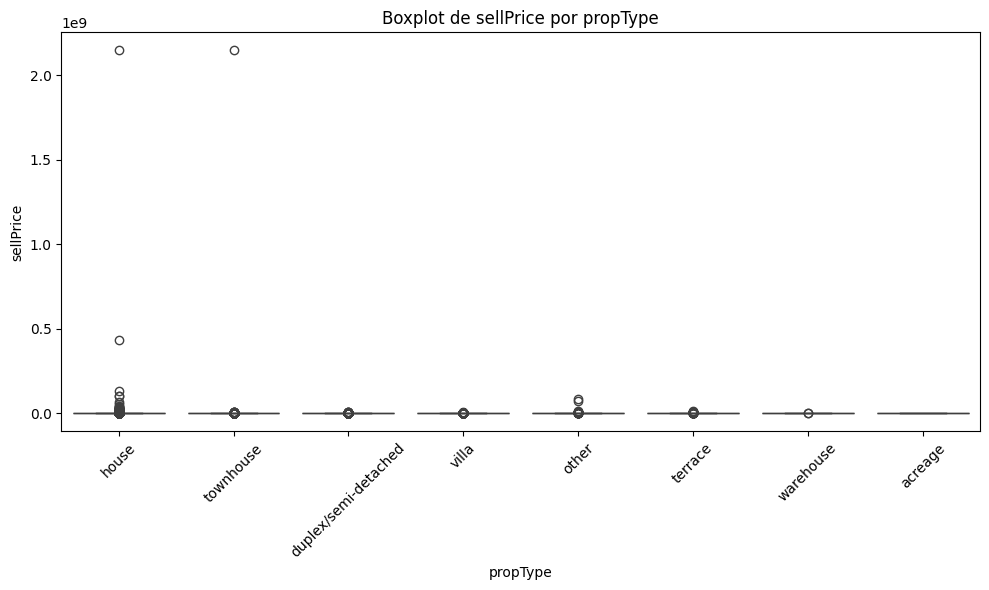

,outliers_inferiores,outliers_superiores
0,640.0,2640000
1,1650.0,1990000
2,524.0,2800000
3,443.0,1959000
4,1000.0,3020000
...,...,...
10919,NaN,1550000
10920,NaN,1300000
10921,NaN,1430000
10922,NaN,4180000


In [41]:
analizar_outliers(df, columna_numerica='sellPrice', columna_categorica='propType')

---